# TP2 : Extraction d'information


## Préparation des données



### Imports

In [54]:
import os


### Choix de l'année et vérification de l'accès aux fichiers

In [55]:

# Choix de l'année
year = 1949

# Chemin vers les fichiers texte 
txt_path = '../../data/txt'

In [56]:
# Liste des fichiers de 1949
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and str(year) in f]
len(txts)

100

## Mots-clés


### Imports

In [57]:
import yake

### Essai avec 1 fichier

In [58]:
# Instantier l'extracteur de mots clés
kw_extractor = yake.KeywordExtractor(lan="fr", top=50)
kw_extractor

In [59]:
# Choisir un fichier
this_file = txts[0]
this_file

# Récupérer le texte du fichier
text = open(os.path.join(txt_path, this_file), 'r', encoding='utf-8').read()
text[:500]

"63* ANNEE — N° 2 ». •’•» ÏOUBNAL QUOTIDIEN 4 Pages-Iir.25 France: 13 fr. franç. —> Suisse: 0 fr. 35 suisse CHEQUES POSTAUX : PUBLICITE : Compte n* 5675 Boesèl & C u VENTE : Soir et Soir Illustré : 14686 Bossel et C 1 * DONS aux Œuvres du Soir : 14232 Bossel et C* Les maaascrits non insérés ne sont pas rendus SEDUCTION t 21. PLACE UE LOUVAIN, 21 VENTE ET ABONN. : PLACE DE LOUVAIN, 23 ANNONCÉS î AG. 'BOSSEL. BUE BOYALE, 122 SALLE DE DEPECHES ! RUE BOYALE, 124 — BRUXELLES BUREAUX : PARIS. 10, rue d"

In [60]:
# Extraire les mots clés de ce texte
keywords = kw_extractor.extract_keywords(text)
keywords

[('Tell Aviv', np.float64(0.006229628843759752)),
 ('Janvier', np.float64(0.010285336338878272)),
 ('gouvernement', np.float64(0.015229444000799291)),
 ('Soir', np.float64(0.018597459525415912)),
 ('Aviv', np.float64(0.020684234303065048)),
 ('LONDRES', np.float64(0.021634737039558125)),
 ('Caire Tell Aviv', np.float64(0.0231510758028533)),
 ('Tell', np.float64(0.02550047756906971)),
 ('nuit', np.float64(0.02913440922340206)),
 ('paix', np.float64(0.029996758248772484)),
 ('suisse CHEQUES POSTAUX', np.float64(0.033714106680947924)),
 ('sterling', np.float64(0.03497351840899521)),
 ('Nouvel', np.float64(0.03755047932709011)),
 ('ÏOUBNAL QUOTIDIEN', np.float64(0.03926587414064502)),
 ('l’année', np.float64(0.040500354344414576)),
 ('d’un', np.float64(0.0405329240829189)),
 ('guerre', np.float64(0.04690225045756586)),
 ('Reuter', np.float64(0.04893471063223419)),
 ('cours', np.float64(0.04934015651147171)),
 ('marchés', np.float64(0.05109886318657488)),
 ('déclaré', np.float64(0.055389683

In [61]:
# Ne garder que les bigrammes
kept = []
for kw, score in keywords:
    words = kw.split()
    if len(words) == 2:
        kept.append(kw)
kept

['Tell Aviv',
 'ÏOUBNAL QUOTIDIEN',
 'samedi soir',
 'Richard Berchard',
 'd’autre part',
 'vendredi soir',
 'Soir Illustré']

### Avec tous les fichiers sur 1949

#### Mots-clés fichier par fichier

In [62]:
# Pour 20 fichiers
for f in sorted(txts)[:20]:
    text = open(os.path.join(txt_path, f), 'r', encoding="utf-8").read()
    keywords = kw_extractor.extract_keywords(text)
    kept = []
    for kw, score in keywords:
        words = kw.split()
        if len(words) == 2:
            kept.append(kw)
    print(f"{f} mentions these keywords: {', '.join(kept)}...")

KB_JB838_1949-01-03_01-00001.txt mentions these keywords: Tell Aviv, ÏOUBNAL QUOTIDIEN, samedi soir, Richard Berchard, d’autre part, vendredi soir, Soir Illustré...
KB_JB838_1949-01-06_01-00012.txt mentions these keywords: AGENCE ROSSEL, l’AGENCE ROSSEL, Ecrire Agence, Faire offre, Ecrire Ag.Rossel, Bruxelles dem, Bruxelles cherche, BRUXELLES demande, FIRME IMPORTANTE, cherche place, Demande REPRESENTANTS...
KB_JB838_1949-01-11_01-00008.txt mentions these keywords: BLANCHEUR NATURELLE, SAVONNERIES LEVER, LEVER FRERES, SUNLIGHT Assure, Agence Rossel, Rue Royale, mais. rent, Office Propriétaires, LOUER Maison, SOIR SUNLIGHT, maison rentier, CINEMAS ABC...
KB_JB838_1949-01-13_01-00002.txt mentions these keywords: Eve Francis, qu’Eve Francis, Temps héroïques, théâtre Eve, Jean Giraudoux, d’Eve Francis...
KB_JB838_1949-01-18_01-00008.txt mentions these keywords: Agence Rossel, rue Royale, Bruxelles Tél, louer maison, Forest Tél, Libre Bruxelles...
KB_JB838_1949-01-19_01-00006.txt mentions t

#### Mots-clés de toute l'année

In [63]:
# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

In [64]:
# Texte de toute l'année 1949
text = ' '.join(content_list)
len(text)

3852678

In [65]:
# Compter le nombre de fichiers
len(content_list)

100

In [66]:
# Ecrire tout le contenu dans un fichier temporaire
temp_path = '../../data/tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

In [67]:
# Imprimer le contenu du fichier et constater les "déchets"
with open(os.path.join(temp_path, f'{year}.txt'), 'r', encoding='utf-8') as f:
    before = f.read()

before[:500]

"63* ANNEE — N° 2 ». •’•» ÏOUBNAL QUOTIDIEN 4 Pages-Iir.25 France: 13 fr. franç. —> Suisse: 0 fr. 35 suisse CHEQUES POSTAUX : PUBLICITE : Compte n* 5675 Boesèl & C u VENTE : Soir et Soir Illustré : 14686 Bossel et C 1 * DONS aux Œuvres du Soir : 14232 Bossel et C* Les maaascrits non insérés ne sont pas rendus SEDUCTION t 21. PLACE UE LOUVAIN, 21 VENTE ET ABONN. : PLACE DE LOUVAIN, 23 ANNONCÉS î AG. 'BOSSEL. BUE BOYALE, 122 SALLE DE DEPECHES ! RUE BOYALE, 124 — BRUXELLES BUREAUX : PARIS. 10, rue d"

In [68]:
# Extraire les mots clés de l'année
keywords = kw_extractor.extract_keywords(text)
keywords

[('Ecrire Agence Rossel', np.float64(2.261066648225967e-06)),
 ('Tél', np.float64(1.0833137522598043e-05)),
 ('BRUXELLES', np.float64(1.2684507784543877e-05)),
 ('ROSSEL RUE ROYALE', np.float64(1.4225930922201833e-05)),
 ('Bruxelles Tél', np.float64(1.5493171256141913e-05)),
 ('RUE', np.float64(1.6104020486656436e-05)),
 ('Bruxelles Anvers Tél', np.float64(1.862601393474564e-05)),
 ('Van', np.float64(2.0797379924040945e-05)),
 ('AGENCE ROSSEL', np.float64(2.4679269201129902e-05)),
 ('rue Van', np.float64(2.517757276892938e-05)),
 ('Rossel', np.float64(2.5615086812851847e-05)),
 ('MAISON BELGE Tél', np.float64(2.7630619147506696e-05)),
 ('prix', np.float64(3.124477364157428e-05)),
 ('RUE ROYALE', np.float64(3.253093137848506e-05)),
 ('prix Agence Rossel', np.float64(3.522757022409938e-05)),
 ('rue Royale Bruxelles', np.float64(4.1563836533663413e-05)),
 ('BRUXELLES MAISON BELGE', np.float64(4.567932185666841e-05)),
 ('AGENCE ROSSEL Bruxelles', np.float64(5.0687698642311833e-05)),
 ('gra

## Nuage de mots


### Imports

In [69]:
from collections import Counter
from wordcloud import WordCloud
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\olivi\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


### Liste des mots vides

In [70]:
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem"]
# mots vides ajoutés avec chaque itération
sw += ["tél", "rue", "bruxelles", "prix", "ans", "ecr", "ecrire", "app", "bon", "très"]
sw += ["grand", "brux", "maison", "part", "place", "libre", "louer", "mois", "soir"]
sw += ["leurs", "peu", "mod", "heures", "saint", "belgique", "belge",]
sw += ["conf", "cuis", "bat", "bel", "demande", "vendre", "agence", "lieu", "etc",
       "cours", "avant", "mme", "bonne", "belle", "jour", "première", "toute", "temps"]
sw += ["vente", "vend", "pers", "eau", "vue", "centre", "francs",
       "quelques", "partie", "chez", "fin", "point", "ordre", "juillet", "juin"]
sw += ["cherche", "neuf", "pet", "avenue", "appart", "midi", "dimanche", "mai",
       "suite", "fois", "beau", "devant", "vers","car"]
sw += ["grande"]

sw = set(sw)

### Nettoyage

In [71]:
# Créer la fonction de nettoyage
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

In [72]:
# Appliquer la formule
clean_text(year, folder=temp_path)


'Output has been written in ../../data/tmp/1949_clean.txt!'

In [73]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'ANNEE ÏOUBNAL QUOTIDIEN PAGES IIR FRANCE FRANÇ SUISSE SUISSE CHEQUES POSTAUX PUBLICITE COMPTE BOESÈL ILLUSTRÉ BOSSEL DONS ŒUVRES BOSSEL MAAASCRITS INSÉRÉS RENDUS SEDUCTION LOUVAIN ABONN LOUVAIN ANNONCÉS BOSSEL BUE BOYALE SALLE DEPECHES BOYALE BUREAUX PARIS BOURSE LONDRES OLIICE QUEEN VICTORIA STREET LONDON NEW YORK AUSTIN STREET FOROST HILLS ZURICH MÜHLEBDCHSTRASSE HCK PTEŒLÈTE DEUXIÈME VJR TÏBIRFÈME QUATRIÈME ÉDIT EDITION NUIT ÉDIT NUI LUNDI JANVIER TELEPHONES ÉDITION LIGNE QUELLE HEURE LAQUELL'

### Création du nuage

In [74]:
frequencies = Counter(after.split())
print(frequencies.most_common(25))

[('PAYS', 421), ('ÉTAT', 400), ('FRANCE', 357), ('ANVERS', 349), ('DIVISION', 315), ('PREMIER', 290), ('PARIS', 287), ('MINISTRE', 280), ('FRANÇAIS', 279), ('GÉNÉRAL', 272), ('LOUISE', 268), ('ETAT', 265), ('LOI', 257), ('DAME', 253), ('PRÉSIDENT', 249), ('TRAVAIL', 249), ('VIS', 247), ('UNION', 245), ('TOUR', 241), ('NORD', 240), ('SERVICE', 240), ('VILLA', 238), ('CHAMBRE', 231), ('GUERRE', 230), ('TÉLÉPH', 230)]


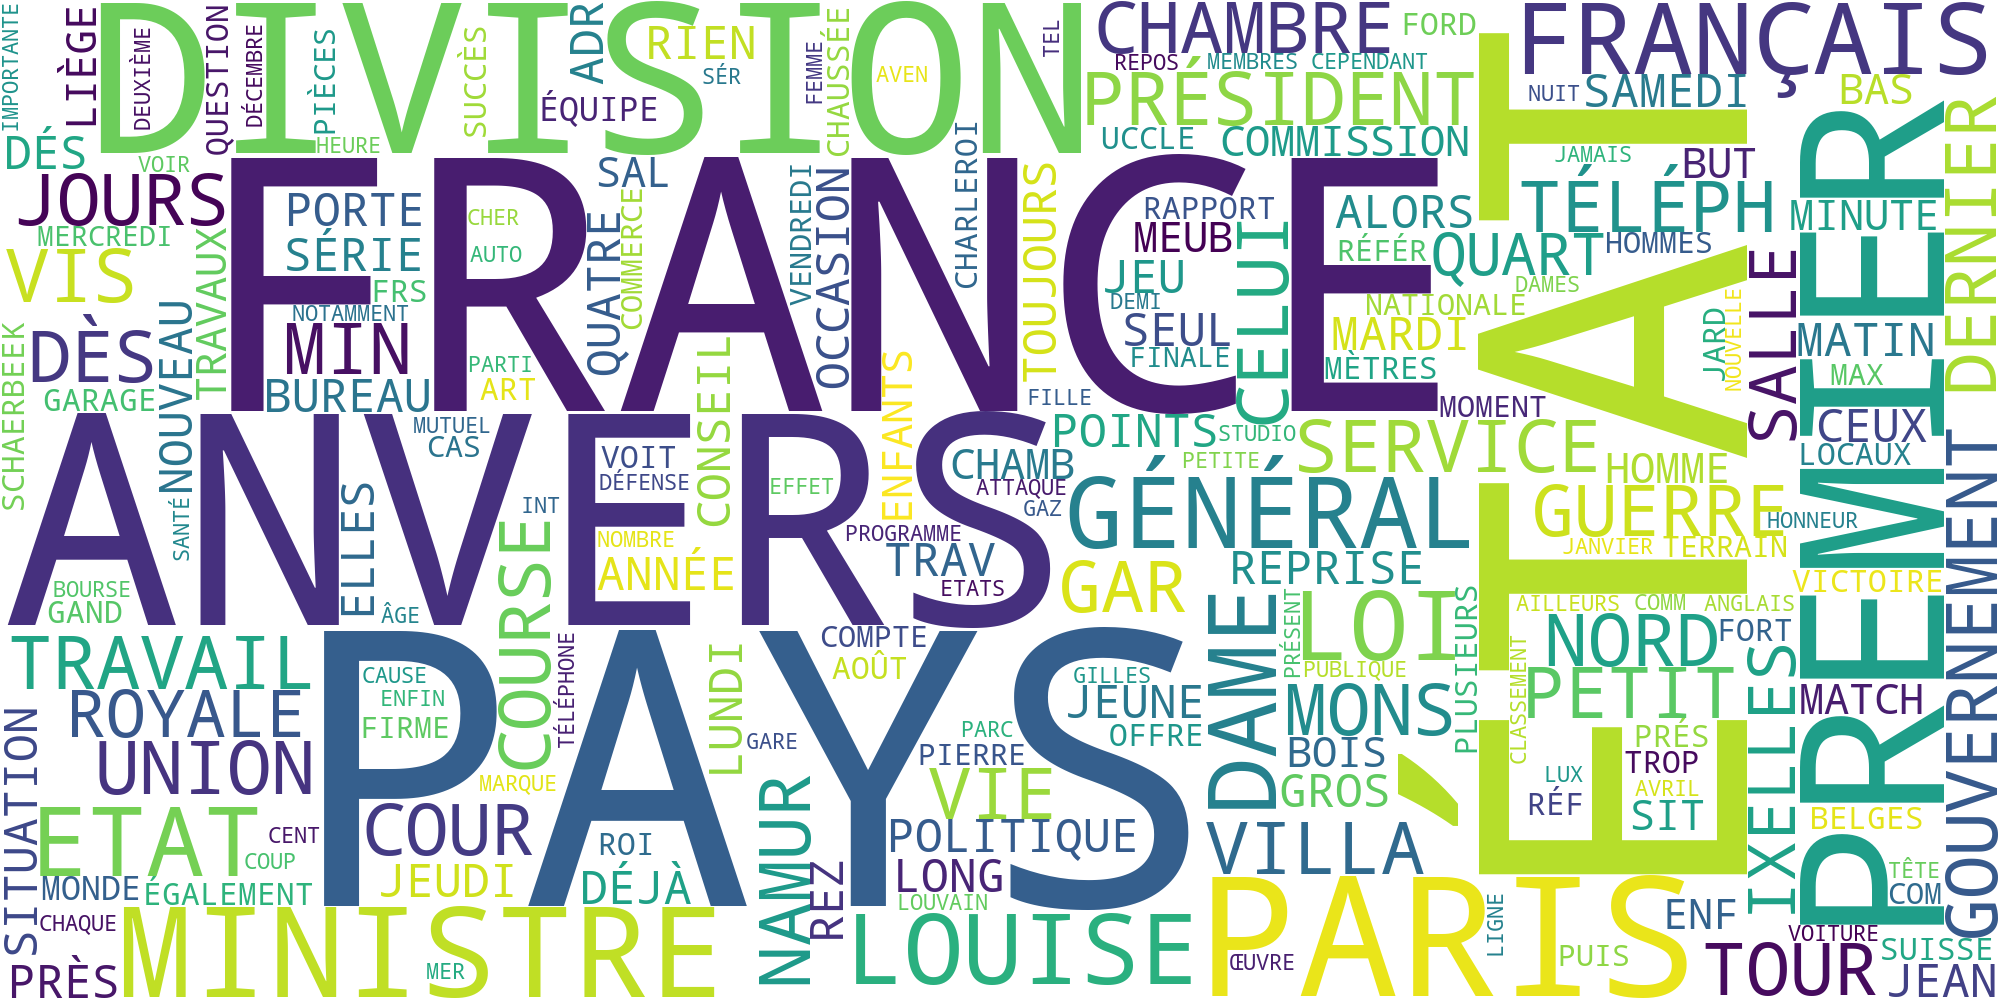

In [75]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))